In [1]:
!python --version

Python 3.8.3


### Initial development

This file presents the code used in the initial development of this repository. Here, simple versions of the DWT and DWPT are implemented and validated.

## to do:


- implement more types of padding
- extend max. db order from 19?

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path

testing
- sine waves 2:1:10 MHz + narrow window + noise
- harmonics [0.5, 1, 2, 3] MHz f0 with and without bandpass

last meeting
- check padding
- check error instead of visual comparison
- inverse transform
- plot nodes with frequency ranges and variance
- graph neural network

In [2]:
# suppresses all testing, does not suppress function definitions
# set to true and run all to define functions, then set to false
# generated sound wave is not suppressed
suppress_all = False

# 0.0 Sine wave simulation
This code creates a sound wave using sound_wave().
The sound wave is made up of randomly selected sin waves over a given range of frequencies given by "bandwidth".
The frequencies making up the signal is tracked in the list "frequencies".

The data is padded to the next power of 2 for transforms

Used in each cell titled 'running...'

In [3]:
import numpy as np
import random
from scipy import signal

def sin(A, frequency, phi, t):
    omega = 2*np.pi*frequency
    sin_wave = A*np.sin(omega*t-phi)
    return sin_wave

def sound_wave(
    A_max, bandwidth, duration, sampling_rate, 
    n = 1, band_range = 1, delay = 0, end = 0, rand = False,
    ):
    ''' 
    Returns a randomly generated sound wave made up of "n" 
    sine waves. The frequencies present in the wave is tracked 
    with the variable "frequencies" This will be plotted in a 
    histogram. Creates a single sine wave by default.

    Parameters
    ----------
    A_max: float
        the maximum amplitude of each sin wave.
    bandwidth: float
        the maximum frequency of each sin wave.
    duration: float
        the time duration of the signal.
    sampling_rate: float
        sampling_rate of the sensor in hz
    n: int
        number of sine waves to be added to the signal
    band_range: float
        the frequency is selected from the last "band_range"
        (e.g. 1/4) of the selected bandwidth
    delay: float
        a time delay for the signal.
    end: float
        time that the signal ends at.
    rand: boolean
        choose whether to randomise the frequency, phase, 
        and amplitude of the sin wives. Set to False to 
        suppress randomness.
    fundamental_frequency: float
        if this is passed, n harmonics will be added together 
        to form the wave
    '''

    frequencies = []
    t = np.arange(0,duration,1/sampling_rate)
    wave = np.zeros(int(len(t)))

    # initialise parameters for non-random case
    A = A_max
    phi = 0
    frequency = bandwidth

    for i in range(n):
        if rand:
            A,phi,frequency = rand_wave_params(A_max,band_range,bandwidth)
        # generate sine wave
        sin_wave = sin(A,frequency,phi,t)
        # add sine wave to total wave
        wave = wave + sin_wave     
        # track the frequency of the sine wave added
        frequencies.append(frequency)

    # add delay and end
    delay_index = find_delay_index(t,delay)
    end_index = find_end_index(t,end)

    wave[:delay_index] = 0
    wave[end_index:] = 0
    
    return wave, t, frequencies 

def rand_wave_params(A_max,band_range,bandwidth):
    A = A_max*random.random()
    phi = 2*np.pi*random.random()
    frequency = bandwidth*(1-band_range*random.random())
    return A,phi,frequency

def noise(standard_deviation, duration, sampling_rate):
    t = np.arange(0,duration,1/sampling_rate)
    noise = np.random.normal(0,standard_deviation,len(t))
    return noise

def find_delay_index(t,delay):
    'finds the index of the start of the delayed signal'
    for delay_index in range(len(t)):
        if t[delay_index] > delay:
            return delay_index

def find_end_index(t,end):
    'finds the index of the end of the cut off signal'
    end_index = len(t) - 1
    for _ in range(len(t)):
        if t[end_index] < end:
            return end_index
        end_index -= 1

def pad_data(data):
    'zero pads the data to the nearest power of 2'
    i = 1
    while True:
        if len(data) < i:
            added_zeros = i-len(data)
            padded_data = np.pad(data,(0,added_zeros))
            return padded_data, added_zeros
        i *= 2

def window(data,type = 'hanning'):
    if type == 'hanning':
        data *= np.hanning(len(data))
    elif type == 'gaussian':
        data *= signal.windows.gaussian(len(data),1)
    return data*np.hanning(len(data))

### 0.1 Noisy Sin Wave

testing with a sin wave which exists between 'delay' and 'end' seconds.
data_pad is used as the input signal for the rest of the code.

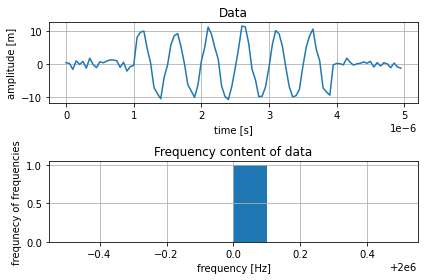

In [4]:
import matplotlib.pyplot as plt

# set parameters
randomise = False # set to true to randomise the sine waves

number_of_sin_waves = 1 # arbitrary conditions
max_amp_sin_waves = 10
sampling_rate = 20*10**6

max_frequency = 2*10**6 # change frequency content. = frequency of non-randomised wave
band_range = 1 # only if randomise == True

time_period = 1/max_frequency
signal_duration = 10*time_period # full signal duration, signal exists between delay and end
delay = 2*time_period
end = 8*time_period

gaussian_noise_std = 1 # set the standard devaition of the noise

# generate data
nyquist_frequency = sampling_rate/2

data, t_plot, frequencies = sound_wave(
    max_amp_sin_waves, max_frequency, signal_duration, 
    sampling_rate, number_of_sin_waves, band_range, delay, 
    end, randomise
    )
gaussian_noise = noise(gaussian_noise_std,signal_duration,sampling_rate)
data += gaussian_noise
data_pad, added_zeros = pad_data(data)

fig, ax = plt.subplots(2,1)

ax[0].plot(t_plot,data)
ax[0].set_xlabel('time [s]')
ax[0].set_ylabel('amplitude [m]')
ax[0].set_title('Data')
ax[0].grid(True)

ax[1].hist(frequencies)
ax[1].set_xlabel('frequency [Hz]')
ax[1].set_ylabel('frequnecy of frequencies')
ax[1].set_title('Frequency content of data')
ax[1].grid(True)

fig.tight_layout()

plt.show()

# for future plots
if randomise:
    bandwidth_low = max_frequency*(1-band_range)
    title = "- signal bandwidth = " + bandwidth_low +"-" + max_frequency + " Hz"
else:
    title = "- signal frequency = " + str(max_frequency) + " Hz"


# 1.1 The Haar Transform

The sound wave is generated using sound_wave() and then the discrete haar wavelet transform is computed with haar_transform().

The wave is first padded the nearest power of 2 because this algorithm cannot handle an arbitrary data set.

The coefficients are stored in one array where the second half contains the coefficients for the smallest scale wavelet, the second quarter contains the coefficients for a wavelet of twice the scale etc.

In [5]:
def haar_transform(data, levels):
    output = [0 for i in range(len(data))]
    length = int(len(data)/2)   
    # length is the current length of the working area of the output array.
    #length starts at half of the array size and every iteration is halved
    for _ in range(levels):
        for i in range(length):
            approx = data[i*2] + data[i*2+1]
            approx *= 1/np.sqrt(2)
            detail = data[i*2] - data[i*2+1]
            detail *= 1/np.sqrt(2)
            output[i] = approx
            output[length + i] = detail
        data = output.copy() #swap arrays for next iteration
        length = int(length/2)
    return output

def max_level_check(data, levels, db_order = 1):
    'checks if there are too many levels'
    no_sections = int(2**levels)
    if db_order > 1:
        if len(data)/no_sections < db_order*2:
            print('too many levels')
            print('length of the data is: ',len(data),)
            return False
    elif no_sections > len(data):
        print('too many levels')    
        print(
            '''
            length of data is: {}, this many levels 
            requires {} data points
            '''.format(len(data),no_sections)
              )
        return False
    return True


### 1.2 Plotting the haar transform

Creating plots of the coefficients in the output array. plot_section() will plot a section of the graph corresponding to frequency bands. plot_array() plots the entire array. plot_frequencies() creates a histogram of the frequencies of the sin waves present in the sound wave.

plot() pulls together all the useful plots

In [6]:
def plot_sections(coefficients, ax, levels, nyquist_freuquecy, added_zeros):
    'plots all sections is a regular transform'

    # calculating number of sections
    length = len(coefficients)
    number_of_sections = levels + 1
    section_length = int(length/2**levels)

    # making plots
    section_counter = 1
    lower_bound = 0
    upper_bound = lower_bound + section_length

    # plot detail coefficients
    for row in range(number_of_sections):
        ax[row].plot([i for i in range(lower_bound,upper_bound)],
                     coefficients[lower_bound:upper_bound])
        ax[row].set_xlabel('Coefficient number')
        ax[row].set_ylabel('Magnitude')
        
        # calculate frequency range and create title
        lower_frequency = lower_bound/length*nyquist_freuquecy
        upper_frequency = upper_bound/length*nyquist_freuquecy

        title = f'''
        Coefficients, {lower_frequency}-{upper_frequency} Hz
        [section {section_counter} of {number_of_sections}]
        '''
        ax[row].set_title(title)
        ax[row].grid(True)

        # update section bounds
        if section_counter != 1:
            section_length *= 2
        lower_bound = upper_bound
        upper_bound = lower_bound + section_length

        section_counter += 1


def plot_all_coefficients(coefficients, ax, title):
    ax.plot(coefficients)
    ax.set_title(f"Coefficients {title}")
    ax.set_xlabel("Coefficient Number")
    ax.set_ylabel("Coefficient")
    ax.grid(True)

def plot_frequencies(frequencies, ax, title):
    'creates a histogram of the frequencies present in the synthetic data'
    ax.hist(frequencies)
    ax.set_title(f"Frequency Distribution {title}")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Frequency of frequency")
    ax.grid(True)

def plot_wave(data, t_plot, ax):
    'plots the data'
    ax.plot(t_plot,data)
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Amplitude [m]")
    ax.set_title("Data")
    ax.grid(True)

def plot(data, t_plot, coefficients, frequencies, title,
         levels, nyquist_frequency, added_zeros):
    'combines relevant plots'

    fig_1, ax_1 = plt.subplots()
    plot_wave(data, t_plot, ax_1)

    fig_2, ax_2 = plt.subplots(2,1)
    plot_all_coefficients(coefficients, ax_2[0], title)
    plot_frequencies(frequencies, ax_2[1], title)

    number_of_sections = int(levels + 1)
    fig_3, ax_3 = plt.subplots(number_of_sections)
    plot_sections(coefficients, ax_3, levels, nyquist_frequency, added_zeros)

    fig_3.set_size_inches(18.5, 2.5*number_of_sections)

    fig_1.tight_layout()
    fig_2.tight_layout()
    fig_3.tight_layout()

    plt.show

### 1.3 Testing

Further testing of the haar transform with examples from pywavelet.

The calculations check out

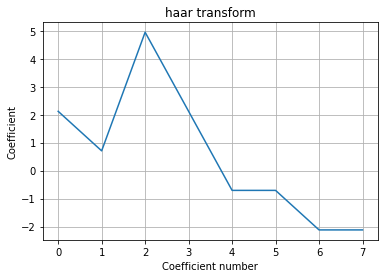

[2.1213203435596424, 0.7071067811865475, 4.949747468305832, 2.1213203435596424, -0.7071067811865475, -0.7071067811865475, -2.1213203435596424, -2.1213203435596424]


In [7]:
run = 1

if suppress_all:
    run = 0

if run:
    data_test = [1,2,0,1,2,5,0,3]

    levels = 1
    x = haar_transform(data_test,levels)

    fig,ax = plt.subplots()
    ax.plot(x)
    ax.set_title('haar transform')
    ax.set_xlabel('Coefficient number')
    ax.set_ylabel('Coefficient')
    ax.grid(True)
    plt.show()

    print(x)

### 1.4 Running the haar wavelet transform

Creating a sound wave, taking its transform and plotting the coefficients generated.
The arguments in sound_wave() can be adjusted to test how the transfrom works with different inputs.

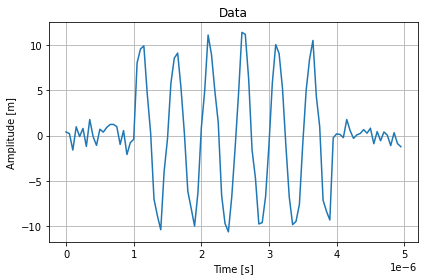

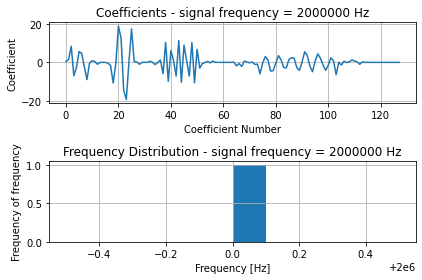

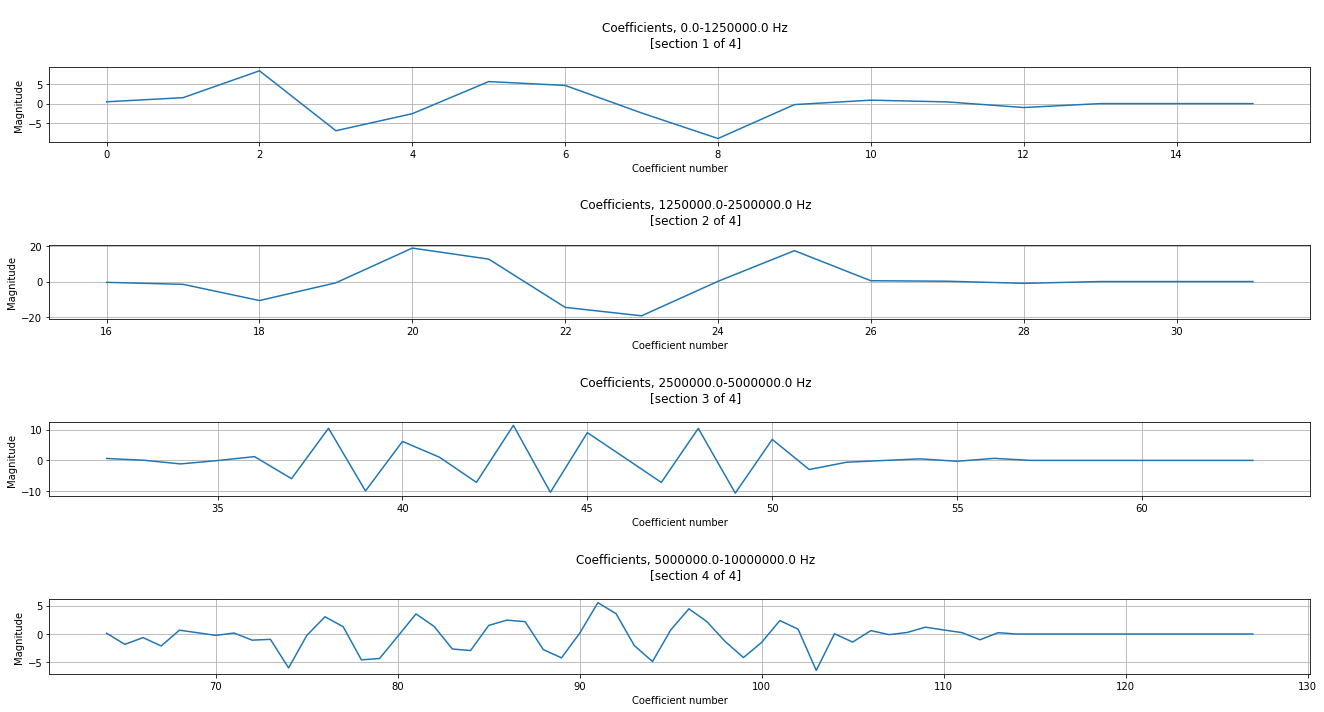

In [8]:
run = 1

if suppress_all:
    run = 0

if run:
    levels = 3

    if max_level_check(data_pad, levels):
        # wavelet transform
        coefficients = haar_transform(data_pad, levels)

        # create plots
        plot(data, t_plot, coefficients, frequencies, title, levels, 
            nyquist_frequency, added_zeros)

## 2.1 Wavelet Packet Transform

This is first completed with the haar wavelet.

In [9]:
def haar_packet_transform(data, levels):
    output = [0 for i in range(len(data))]
    length = int(len(data)/2)
    
    for level in range(levels):
        no_of_filters = int(2**(level)) # the high and low pass filters are repeated 2^(level-1) times per level
        shift = 0 # the filters are applied to different parts of the array.
        for _ in range(no_of_filters):
            for i in range(length):
                approx = data[i*2 + shift] + data[i*2 + shift + 1]
                approx *= 1/np.sqrt(2)
                detail = data[i*2 + shift] - data[i*2 + shift + 1]
                detail *= 1/np.sqrt(2)
                output[i + shift] = approx
                output[length + i + shift] = detail
            shift += int(len(data)/no_of_filters)
        data = output.copy()
        length = int(length/2)
    return output

### 2.2 Plotting the wavelet packet transform
Plots more charts as the number of levels increases to 

In [10]:
def plot_packet_sections(coefficients, ax, levels, nyquist_frequency, added_zeros):
    'plots all sections in the packet transform'

    # calculating section length
    length = len(coefficients)
    number_of_sections, number_of_rows = sections_rows(levels)
    section_length = length/number_of_sections

    # making plots
    section_counter = 1
    for row in range(int(number_of_rows)):
        for column in range(2):    
            lower_bound = int(row*2*section_length + column*section_length)
            upper_bound = int(lower_bound+section_length)
            
            # the charts are trimmed down a bit depending on the number of zeros padded
            trim = int(added_zeros/(2**levels)) 
            ax[row, column].plot([i for i in range(lower_bound,upper_bound-trim)],
                                    coefficients[lower_bound:upper_bound-trim])
            ax[row, column].set_xlabel('Coefficient number')
            ax[row, column].set_ylabel('Magnitude')
            ax[row, column].grid(True)

            # calculate frequency range and create title
            lower_frequency = lower_bound/length*nyquist_frequency
            upper_frequency = upper_bound/length*nyquist_frequency
            
            title = f'''
            Coefficients, {lower_frequency}-{upper_frequency} Hz
            [section {section_counter} of {number_of_sections}]
            '''
            ax[row, column].set_title(title)
            section_counter += 1

def sections_rows(levels):
    'calculates the number of sections and rows for plotting'
    number_of_sections = 2**(levels)
    number_of_rows = int(number_of_sections/2)
    return number_of_sections, number_of_rows

def plot_packet(data, t_plot, coefficients, frequencies, 
                title, levels, nyquist_frequency, added_zeros):
    '''
    plots all sections of the wavelet packet transform
    not used for final packet transform with node class
    '''

    fig_1, ax_1 = plt.subplots()
    plot_wave(data, t_plot, ax_1)

    fig_2, ax_2 = plt.subplots(2)
    plot_all_coefficients(coefficients, ax_2[0], title)
    plot_frequencies(frequencies, ax_2[1], title)

    number_of_sections, number_of_rows = sections_rows(levels)
    fig_3, ax_3 = plt.subplots(number_of_rows, 2)
    plot_packet_sections(coefficients, ax_3, levels, nyquist_frequency, added_zeros)
    fig_3.set_size_inches(18.5, 2.5*number_of_rows)

    fig_1.tight_layout()
    fig_2.tight_layout()
    fig_3.tight_layout()

    plt.show()

### 2.3 Testing packet transform
With matlab

[1.9999999999999996, 4.999999999999998, 1.9999999999999996, 4.999999999999998, 1.9999999999999996, 4.999999999999998, 1.9999999999999996, 4.999999999999998, 0.9999999999999998, 1.9999999999999993, 0.9999999999999998, 1.9999999999999993, 0.9999999999999998, 1.9999999999999993, 0.9999999999999998, 1.9999999999999993, -0.9999999999999998, -2.9999999999999996, -0.9999999999999998, -2.9999999999999996, -0.9999999999999998, -2.9999999999999996, -0.9999999999999998, -2.9999999999999996, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


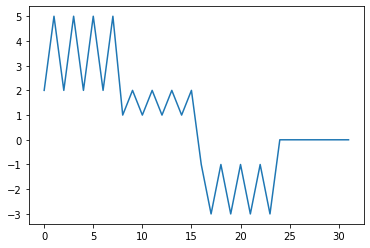

In [11]:
run = 1

if suppress_all:
    run = 0

if run:
    data_test = [1,2,0,1,2,5,0,3]
    data_test = data_test*4
    levels = 2
    x = haar_packet_transform(data_test,levels)

    print(x)

    plt.plot(x)
    plt.show()

### 2.4 Running the packet transform

Using a synthetic sound wave with the same parameters as before.

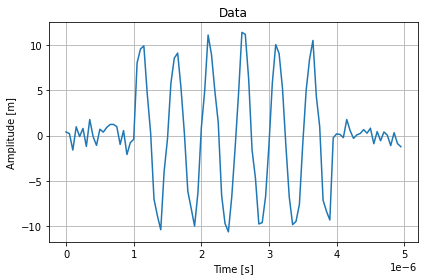

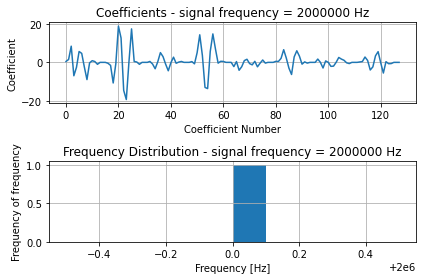

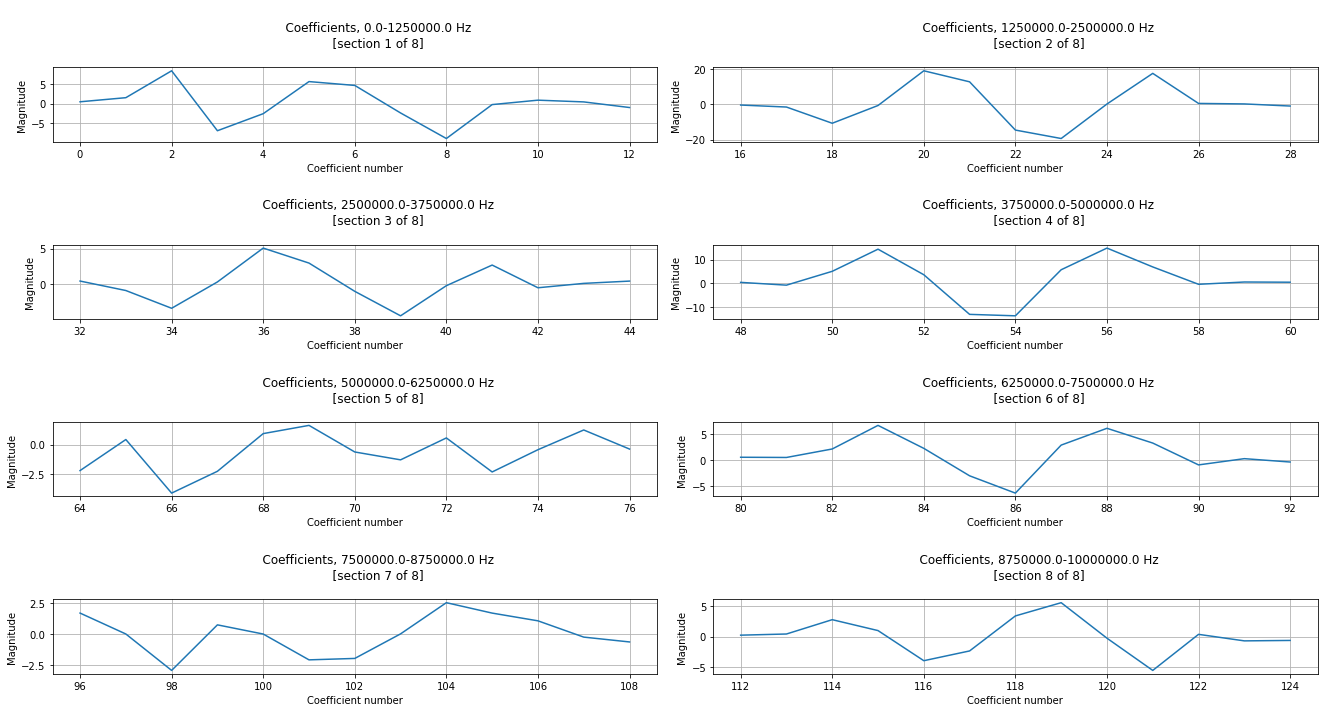

In [12]:
run = 1

if suppress_all:
    run = 0

if run:
    levels = 3 # change number of levels in transform

    if max_level_check(data_pad, levels):
        # transform
        coefficients = haar_packet_transform(data_pad, levels)

        plot_packet(
            data, t_plot, coefficients, frequencies, 
            title, levels, nyquist_frequency, added_zeros)

# 3.1 The Daubechies Wavelet Transform
The daubechies wavelet transform can use waves of any even length. The code is inefficient for order above 30.

In [13]:
def daubechies_transform(data, levels, db_order):
    '''
    takes in data and numeber of levels of transform. returns transform 
    coefficients. n is the number of wave coefficients, this is an even 
    number between 4 and 20.
    '''
    scaling_function_coeffs = db_scaling_coeffs(db_order)
    wave_coeffs = mirror_filter(scaling_function_coeffs)
    scaling_function_coeffs.reverse()
    wave_coeffs.reverse()

    output = [0 for i in range(len(data))]
    length = len(data)

    for _ in range(levels):
        # perform convolutions
        approx = np.convolve(data[:length], scaling_function_coeffs, 'valid')
        detail = np.convolve(data[:length], wave_coeffs, 'valid')

        # downsample
        if len(approx)%2:
            approx = approx[::2]
            detail = detail[::2]
        else:
            approx = approx[1::2]
            detail = detail[1::2]

        length = int(length/2)
        # store in output list    
        for i in range(len(approx)):
            output[i] = approx[i]
            output[i+length] = detail[i]
    
        data = output.copy()
        
    return output

def db_scaling_coeffs(db_order):
    'calculates scaling coefficients for daubechies waves'
    sqrt = np.sqrt
    n = db_order
    # calculate lagrange the order n trous filter 
    # 'a[k] stored in a[k-1]'
    a = np.zeros(4*n-1)
    for k in range(1,n+1):
        num = 1
        denom = 1
        for i in range(-n+1,n+1):
            if i == k:
                continue
            num *= (1/2-i)
            denom *= (k-i)
        a_k = num/denom
        a[2*(n-k)] = a_k
        a[2*(n+k-1)] = a_k
    a[2*n-1] = 1
    p = a/sqrt(2)

    # calculate filter coefficients from symmetric filter
    rp = np.roots(p)
    coefficients_roots = [] # find root in unit circle
    for root in rp:
        if abs(root) <= 1:
            coefficients_roots.append(root)
    # find smallest roots
    sorted_coefficients = sorted(coefficients_roots, key = abs)
    coefficients_roots = sorted_coefficients[:n-1]
    
    # add n -1s to roots
    for _ in range(n):
        coefficients_roots.append(-1)
    coefficients = np.poly(coefficients_roots)
    coefficients *= sqrt(2)/sum(coefficients)
    coefficients = list(coefficients)

    return coefficients

def mirror_filter(db_scaling_coeffs):
    coefficients = []
    a = 1
    for i in db_scaling_coeffs:
        coefficients.insert(0,i*(-1)**a)
        a += 1
    return coefficients


### 3.2 Daubechies test

Using matlab to find the same transfrom and comparing the numbers.

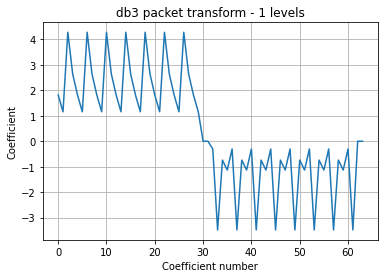

In [14]:
run = 1

if suppress_all:
    run = 0

if run:
    data_test = [1,2,0,1,2,5,0,3]
    data_test = 8*data_test

    db_order = 3
    levels = 1
    x = daubechies_transform(data_test,levels,db_order)

    fig,ax = plt.subplots()
    ax.set_title(f'db{db_order} packet transform - {levels} levels')
    ax.set_xlabel('Coefficient number')
    ax.set_ylabel('Coefficient')
    ax.plot(x)
    plt.grid(True,'both')
    plt.show()

### 3.3 Running the Daubechies transform

The code requires some zeros at the end of the array. This is usually covered by zero padding.

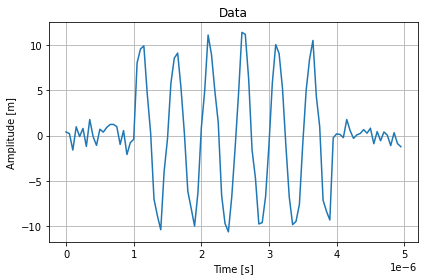

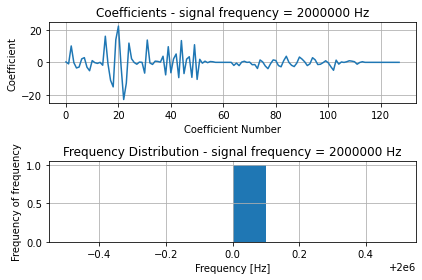

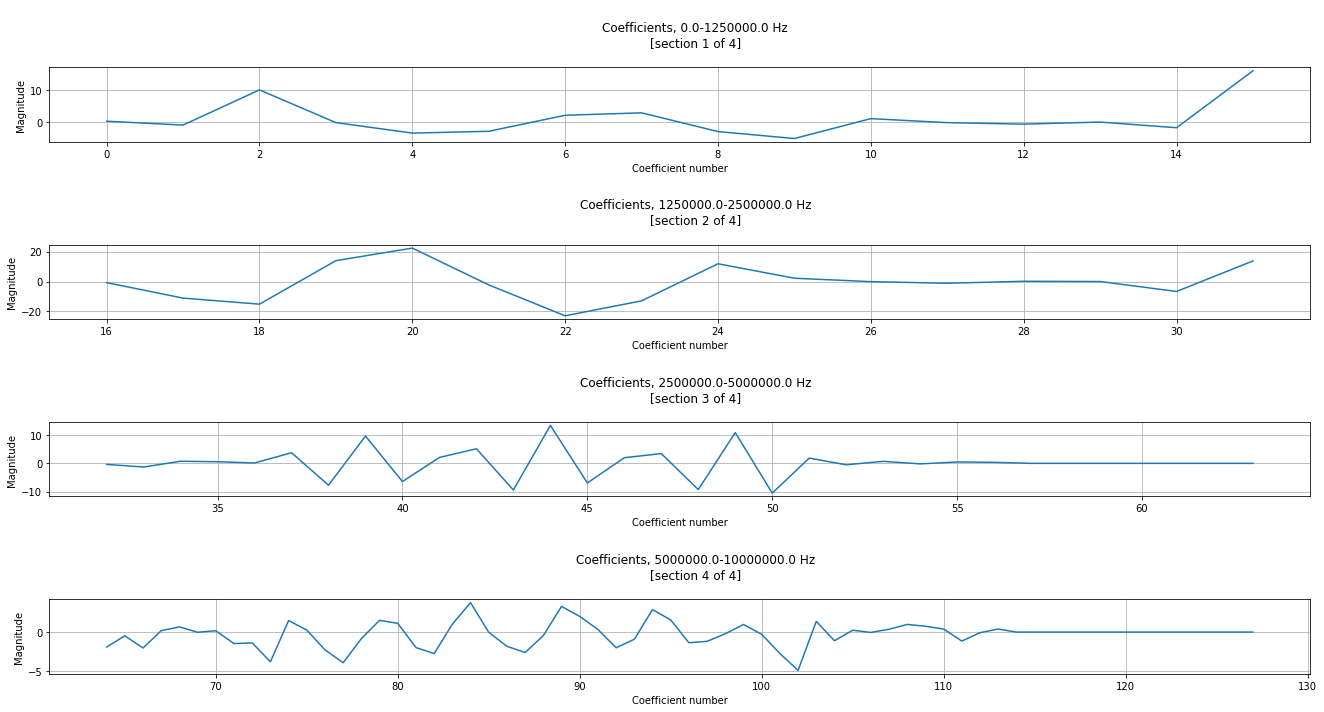

In [15]:
run = 1

if suppress_all:
    run = 0

if run:
    levels = 3 # change number of levels in transform
    db_order = 2

    if max_level_check(data_pad, levels):
        # transform
        coefficients = daubechies_transform(data_pad, levels, db_order)

        # create plots
        plot(
            data, t_plot, coefficients, frequencies, 
            title, levels, nyquist_frequency, added_zeros
            )

# 4.1 Daubechies Packet Transform
A new packet transform is defined using nodes. 

Symmetric padding has been implemented.

This was extended to the daubechies dwt as well.

In [16]:
class Node():
    def __init__(
        self, parent = None, type = None, filter_coeffs = None, 
        mode = 'sym', data = None
        ):
        if parent == None: # base node
            self.data = data
            self.path = ''
        else:
            self.parent = parent
            self.path = f'{parent.path}{type}' # eg 'aaa' for 3rd level approx
            self.data = self.filter(filter_coeffs, mode)
        self.energy = self.energy_calc()

    def filter(self, filter_coeffs, mode):
        'performs the convolution between an adapted signal and the filter'
        parent_data = self.parent.data

        # symmetric extension
        if mode == 'sym':
            # add reversed signal onto itself
            parent_data_rev = parent_data.copy()
            parent_data_rev = np.flip(parent_data_rev)

            length = len(filter_coeffs) - 2
            front = np.array([])
            end = np.array([])
            for _ in range(length): # check if length == 0
                front = parent_data_rev[-length:]
                end = parent_data_rev[:length]
                break
            data = np.concatenate((front,parent_data,end))
        elif mode == 'zpd':
            pass

        # perform convolution
        data = np.convolve(data, filter_coeffs, 'valid')
        # downsample
        if len(data)%2:
            data = data[::2]
        else:
            data = data[1::2]
        return data
    
    def energy_calc(self):
        return np.var(self.data)

def dbpt(data, levels, db_order, mode = 'sym'):
    'daubechies packet transform'
    # calculate filter coefficients
    scaling_function_coeffs = db_scaling_coeffs(db_order)
    wave_coeffs = mirror_filter(scaling_function_coeffs)
    scaling_function_coeffs.reverse()
    wave_coeffs.reverse()

    # create lists of nodes
    input_nodes = [] # nodes going into each level of the transform
    all_nodes = [] # nodes at all levels are tracked

    if isinstance(data,list):
        data = np.array(data)
    
    base_node = Node(data = data)
    input_nodes.append(base_node)
    all_nodes.append(base_node)

    for level in range(levels):
        output_nodes = []
        for node in input_nodes:
            # create nodes
            approx_node = Node(node,'a',scaling_function_coeffs,mode)
            detail_node = Node(node,'d',wave_coeffs,mode)
            # store in output array
            output_nodes.append(approx_node)
            output_nodes.append(detail_node)
        all_nodes.append((level,output_nodes))
        input_nodes = output_nodes.copy()

    return output_nodes, all_nodes

def dbwt(data, levels, db_order, mode = 'sym'):
    'daubechies discrete wavelet transform'
    # calculate filter coefficients
    scaling_function_coeffs = db_scaling_coeffs(db_order)
    wave_coeffs = mirror_filter(scaling_function_coeffs)
    scaling_function_coeffs.reverse()
    wave_coeffs.reverse()

    # create lists of nodes
    input_nodes = [] # nodes going into each level of the transform
    all_nodes = [] # nodes at all levels are tracked
    final_nodes = [] # detail coefficients and final approx

    if isinstance(data,list):
        data = np.array(data)
    
    base_node = Node(data = data)
    input_nodes.append(base_node)
    all_nodes.append(base_node)

    for level in range(levels):
        output_nodes = []
        for node in input_nodes:
            # create nodes
            approx_node = Node(node,'a',scaling_function_coeffs,mode)
            detail_node = Node(node,'d',wave_coeffs,mode)
            # store in output array for next level
            output_nodes.append(approx_node)

        all_nodes.append((level,approx_node))
        all_nodes.append((level,detail_node))
        final_nodes.append(detail_node)
        input_nodes = output_nodes.copy()

    final_nodes.append(approx_node)
    final_nodes.reverse()
    return final_nodes, all_nodes



### 4.2 Plotting the dbwp nodes

new plotting scheme for the nodes

In [17]:
def plot_final_nodes(
    nodes, data, t_plot, frequencies, title, 
    levels, nyquist_frequency, trans_type = 'dwt'
    ):

    fig_1, ax_1 = plt.subplots()
    plot_wave(data, t_plot, ax_1)

    fig_2, ax_2 = plt.subplots(2)
    plot_all_final_nodes(nodes, ax_2[0], title)
    plot_frequencies(frequencies, ax_2[1], title) 

    rows = int(len(nodes)/2)
    if trans_type == 'dwt' and not levels%2:
        rows += 1
    fig_3, ax_3 = plt.subplots(rows,2)
    plot_nodes(nodes, ax_3, levels, nyquist_frequency, rows, trans_type)
    fig_3.set_size_inches(18,2.4*rows)

    fig_1.tight_layout()
    fig_2.tight_layout()
    fig_3.tight_layout()
    
    plt.show()

def plot_nodes(nodes, ax, levels, nyquist_frequency, rows, trans_type = 'dwt'):

    # calculation section frequency
    frequency_diff = nyquist_frequency/2**levels
    lower_frequency = 0
    upper_frequency = lower_frequency + frequency_diff

    section_counter = 1
    for row in range(rows):
        for column in range(2):
            # plot coefficients
            try:
                node = nodes[section_counter-1]
            except IndexError:
                break
            if rows == 1:
                axis = ax[column]
            else:
                axis = ax[row, column]
            axis.plot(node.data)
            
            # set labels
            axis.set_xlabel('coefficient number')
            axis.set_ylabel('magnitude')
            axis.grid(True)

            title = f'''
            Coefficients, {lower_frequency}-{upper_frequency} Hz
            [section {section_counter} of {len(nodes)}]
            '''
            axis.set_title(title)

            # re-calculate frequencies
            if trans_type == 'dwt' and section_counter > 1:
                frequency_diff *= 2
            lower_frequency = upper_frequency
            upper_frequency = lower_frequency + frequency_diff

            section_counter += 1

def plot_all_final_nodes(nodes, ax, title):
    output = np.array([])
    for node in nodes:
        output = np.concatenate((output,node.data))
    ax.plot(output)
    ax.set_title(f"Coefficients {title}")
    ax.set_xlabel("Coefficient Number")
    ax.set_ylabel("Coefficient")
    ax.grid(True)

## 4.3 Testing DB packet

with pywt

the generated graphs have the same values, the pywt graphs are a bit messier because the library handles boundaries differently.

works until db18

BEST VIEWED WITH SPLIT SCREEN

### 4.3.1 Plotting library transform

In [18]:
import pywt

def plot_pywp_test(wp_object,levels):
    'just for testing'
    nodes = [node.path for node in wp_object.get_level(levels)]

    # concatenante coefficients
    coeffs = []
    for node in nodes:
        node_data = wp_object[node].data
        coeffs = np.concatenate((coeffs,node_data))

    # plot coefficients
    plt.plot(coeffs)
    plt.grid(True)
    plt.show()

def plot_test(nodes):
    'just for testing'
    # concatenate coefficients
    output = np.array([])
    for node in nodes:
        output = np.concatenate((output,node.data))

    # plot coefficients
    plt.plot(output)
    plt.grid(True)
    plt.show()


# more complete plotting of the wavelet packet object from the library
def plot_pywp(wp_object,levels,nyquist_frequency):
    'more complete plotting of the pywt packet transform'
    nodes = [node.path for node in wp_object.get_level(levels)]
    # plot coefficients
    fig_1, ax_1 = plt.subplots()
    plot_all_pywp(wp_object,ax_1,nodes)

    # plot nodes seperately
    fig_2, ax_2 = plt.subplots(int(len(nodes)/2),2)
    plot_pywp_nodes(wp_object,ax_2,levels,nodes,nyquist_frequency)
    fig_2.set_size_inches(18,2.4*int(len(nodes)/2))

    fig_1.tight_layout()
    fig_2.tight_layout()
    
    plt.show()
    
def plot_pywp_nodes(wp_object, ax, levels, nodes, nyquist_frequency):
    'plot each node seperately'
    rows = int(len(nodes)/2)

    # calculation section frequency
    frequency_diff = nyquist_frequency/2**levels
    lower_frequency = 0
    upper_frequency = lower_frequency + frequency_diff

    section_counter = 1
    for row in range(rows):
        for column in range(2):
            # plot coefficients
            node = nodes[section_counter-1]
            node = wp_object[node]

            if rows == 1:
                axis = ax[column]
            else:
                axis = ax[row, column]
            axis.plot(node.data)
            
            # set labels
            axis.set_xlabel('coefficient number')
            axis.set_ylabel('magnitude')
            axis.grid(True)

            title = f'''
            Coefficients, {lower_frequency}-{upper_frequency} Hz
            [section {section_counter} of {len(nodes)}]
            '''
            axis.set_title(title)

            # re-calculate frequencies
            lower_frequency = upper_frequency
            upper_frequency = lower_frequency + frequency_diff

            section_counter += 1

def plot_all_pywp(wp_object,ax,nodes):
    'plot all nodes in one chart'

    coeffs = np.array([])
    for node in nodes:
        node_data = wp_object[node].data
        coeffs = np.concatenate((coeffs,node_data))
        
    ax.plot(coeffs)
    ax.grid(True)
    ax.set_title('pywt transform')
    ax.set_xlabel('coefficient number')
    ax.set_ylabel('magnitude')

### 4.3.2 My packet result

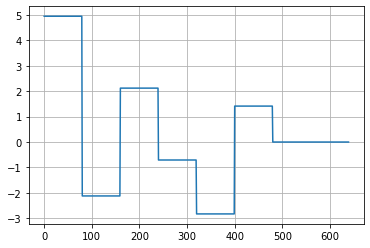

1


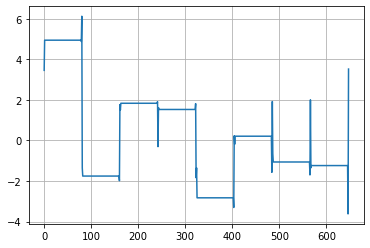

2


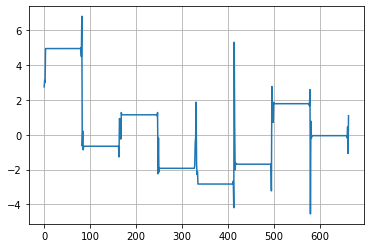

3


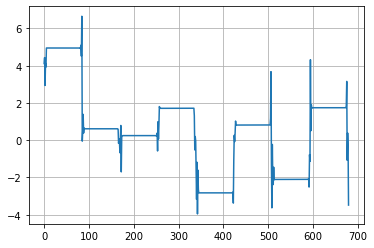

4


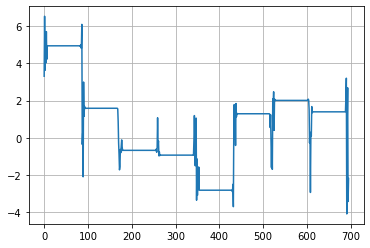

5


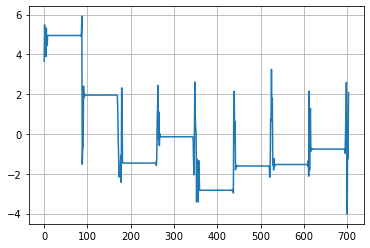

6


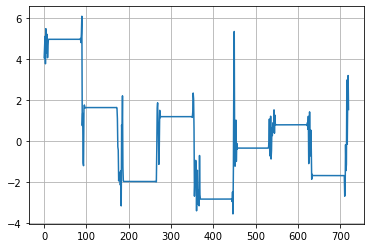

7


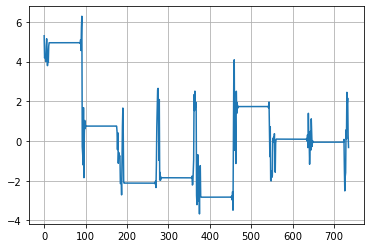

8


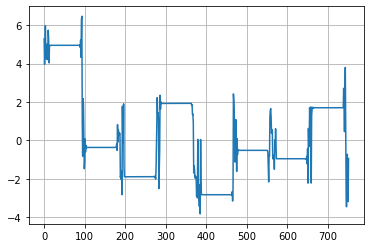

9


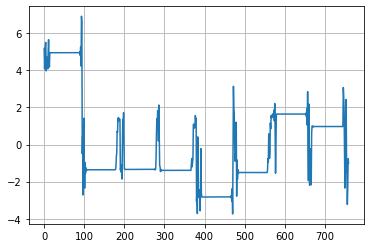

10


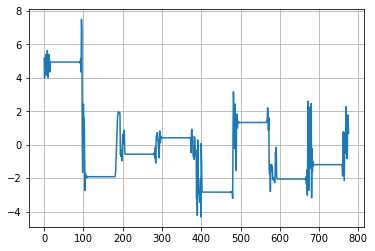

11


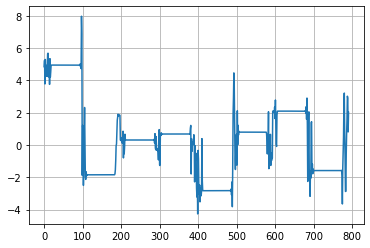

12


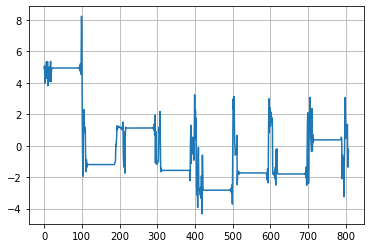

13


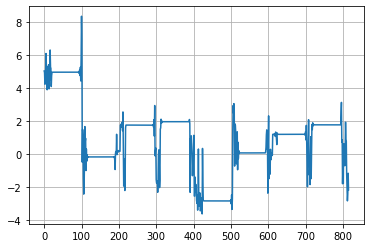

14


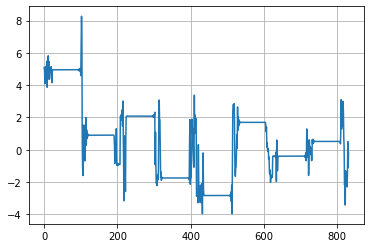

15


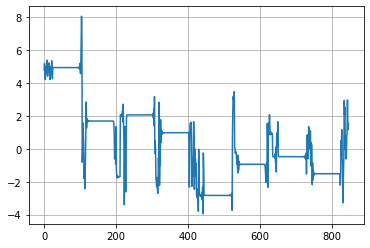

16


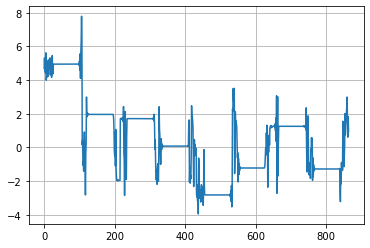

17


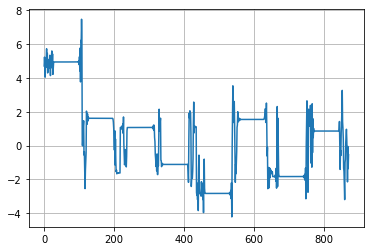

18


In [19]:
run = 1

if suppress_all:
    run = 0

if run:
    data_test = [1,2,0,1,2,5,0,3]
    data_test = 80*data_test

    # set parameters
    levels = 3

    # transform
    for db_order in range(1,19):
        if max_level_check(data_test, levels, db_order):
            x,y = dbpt(data_test,levels,db_order,'sym')
            plot_test(x)
            print(db_order)

### 4.3.3 pywt library packet result

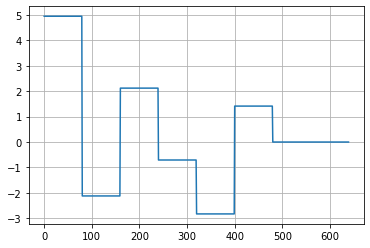

1


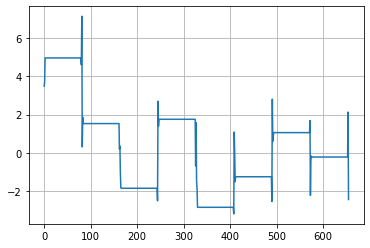

2


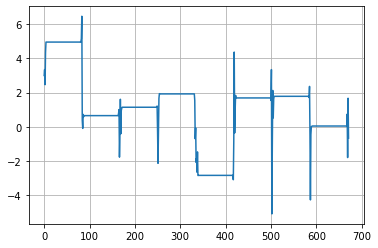

3


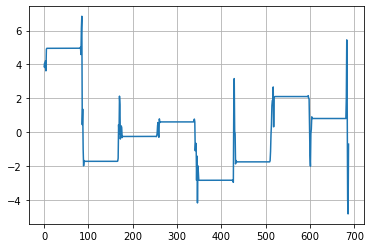

4


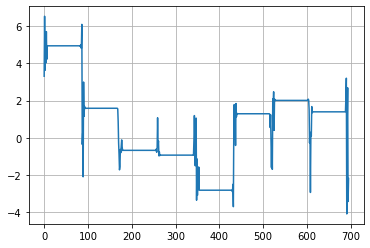

5


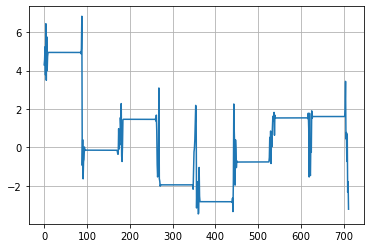

6


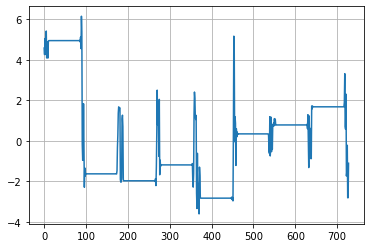

7


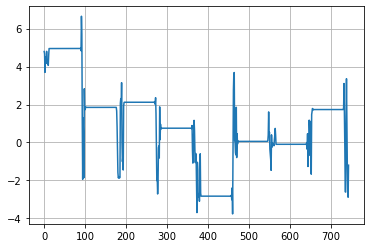

8


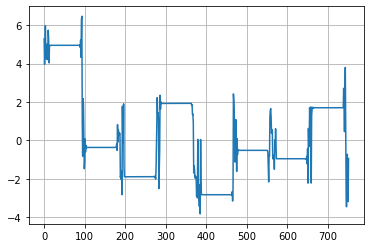

9


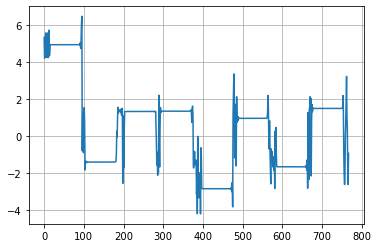

10


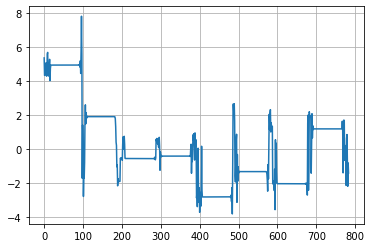

11


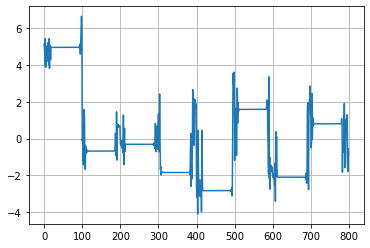

12


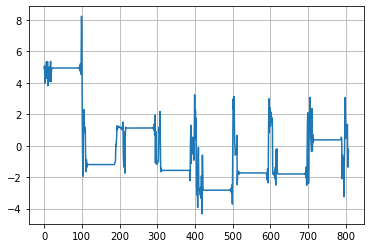

13


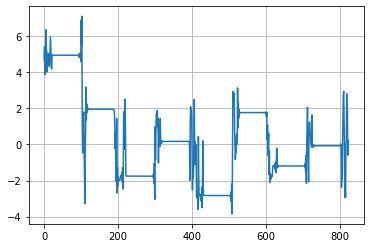

14


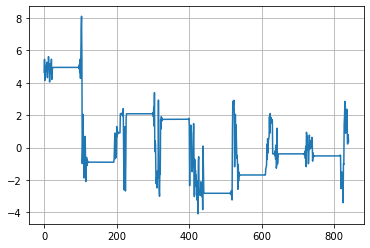

15


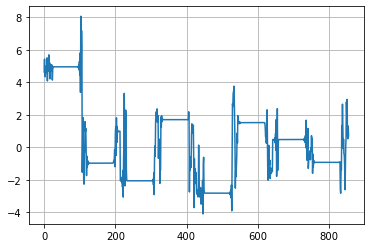

16


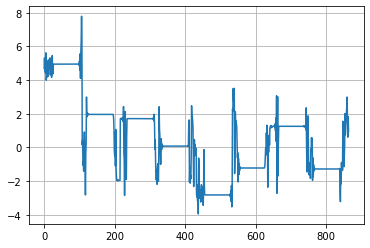

17


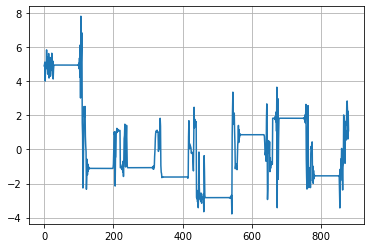

18


In [20]:
run = 1

if suppress_all:
    run = 0

if run:
    data_test = [1,2,0,1,2,5,0,3]
    data_test = 80*data_test

    # set parameters
    levels = 3

    # transform
    for db_order in range(1,19):
        packet_object = pywt.WaveletPacket(data_test, f'db{db_order}')
        plot_pywp_test(packet_object,levels)
        print(db_order)

## 4.4 Running the Daubechies packet transform

Using the data at the top

Compares with pywt, notes the position of the highest amplited in each case given as the node path e.g.:

- a:        approx 1st level
- d:        detail 1st level
- aa:       approx 2nd level
- aad:      detail of approx 2nd level
- adadad:   6th level node

The transforms are very similar.

data_pad no longer has to be used

### 4.4.1 My packet result

In [21]:
run = 1

if suppress_all:
    run = 0

if run:
    # set parameters
    db_order = 10
    levels = 3

    # transform
    if max_level_check(data, levels, db_order):
        final_level_nodes, all_nodes = dbpt(data, levels, db_order)

        # find location of maximum amplitude        
        max_amp = 0
        max_node = None

        for node in final_level_nodes:
            for coefficient in node.data:
                if coefficient > max_amp:
                    max_amp, max_node = coefficient, node.path

        print(f'''maximum amplitude is {max_amp} at node '{max_node}' ''')

        # create plots
        plot_final_nodes(
            final_level_nodes, data, t_plot, frequencies, title, 
            levels, nyquist_frequency, trans_type = 'dwpt'
            )


too many levels
length of the data is:  100


### 4.4.2 pywt result

maximum amplitude is 18.98431256632038 at node 'aa' 


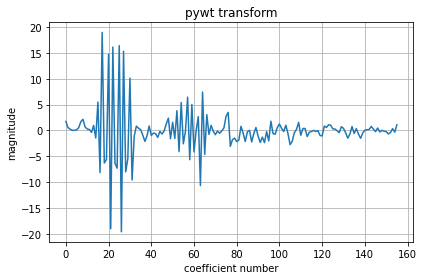

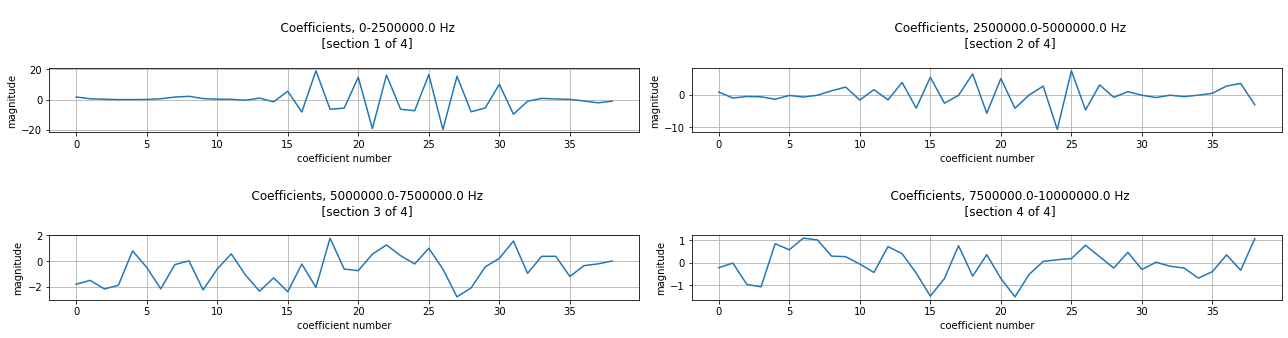

In [22]:
run = 1

if suppress_all:
    run = 0

if run:
    # set parameters
    db_order = 10
    levels = 2

    # transform
    packet_object = pywt.WaveletPacket(data, f'db{db_order}')
    
    # find location of maximum amplitude        
    max_amp = 0
    max_node = None

    nodes = [node.path for node in packet_object.get_level(levels)]
    for node in nodes:
        node_data = packet_object[node].data
        for coefficient in node_data:
            if coefficient > max_amp:
                max_amp, max_node = coefficient, node

    print(f'''maximum amplitude is {max_amp} at node '{max_node}' ''')

    # plot the coefficients
    plot_pywp(packet_object,levels,nyquist_frequency)

### 4.5 New Daubieches transform

Using nodes

### 4.5.1 My results

In [23]:
run = 1

if suppress_all:
    run = 0

if run:
    # set parameters
    db_order = 10
    levels = 3

    # transform
    if max_level_check(data, levels, db_order):
        final_nodes, all_nodes = dbwt(data, levels, db_order)
        # find location of maximum amplitude        
        max_amp = 0
        max_node = None

        for node in final_nodes:
            for coefficient in node.data:
                if coefficient > max_amp:
                    max_amp, max_node = coefficient, node.path

        print(f'''maximum amplitude is {max_amp} at node '{max_node}' ''')

        # create plots
        plot_final_nodes(
            final_nodes, data, t_plot, frequencies, title, 
            levels, nyquist_frequency
            )

too many levels
length of the data is:  100


### 4.5.2 pywt results

/home/optimus2017/anaconda3/lib/python3.8/site-packages/pywt/_multilevel.py:43: UserWarning: Level value of 5 is too high: all coefficients will experience boundary effects.
  warnings.warn(


maximum amplitude is 28.820892005756445 in section 4 


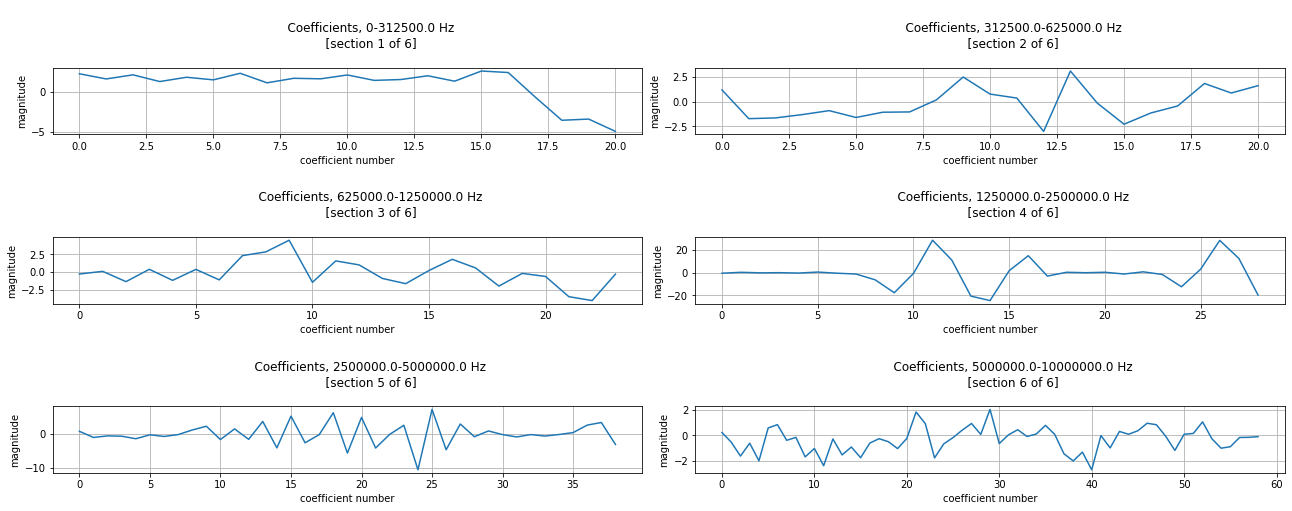

In [24]:
run = 1

if suppress_all:
    run = 0

if run:
    # set parameters
    db_order = 10
    levels = 5

    # transform
    coeffs = pywt.wavedec(data, f'db{db_order}', level = levels)
    
    # find location of maximum amplitude        
    max_amp = 0
    max_node = None

    for i in range(len(coeffs)):
        node = coeffs[i]
        for coefficient in node:
            if coefficient > max_amp:
                max_amp, max_node = coefficient, i+1

    print(f'''maximum amplitude is {max_amp} in section {max_node} ''')

    # plot the coefficients       
    rows = levels//2+1
    fig, ax = plt.subplots(levels//2+1,2)
    plot_nodes(coeffs, ax, levels, nyquist_frequency, rows)

    fig.set_size_inches(18,2.4*rows)
    fig.tight_layout()

# 5.1 Other Wavelets

Incomplete

Implementing Symlets and Coiflets using coefficients from a reference on mathworks [1].

In [25]:
def scaling_coeffs(wave_name):
    sqrt = np.sqrt
    
    if wave_name == 'haar':
        coeffs = db_scaling_coeffs(1)
    elif 'db' in wave_name:
        coeffs = db_scaling_coeffs(wave_name[-1]) 

    elif wave_name == 'sym2':
        coeffs = np.array([0.482962913145,  0.836516303737,  
        0.224143868042, -0.129409522551])
    elif wave_name == 'sym3':
        coeffs = np.array([0.332670552951,0.806891509313,0.459877502119,
        -0.135011020010,-0.085441273882,0.035226291882])

    elif wave_name == 'coif1':
        coeffs = np.arrray([-0.072732619513, 0.337897662458, 0.852572020212, 
        0.384864846864,-0.072732619513,-0.015655728135])
    elif wave_name == 'coif2':
        coeffs = np.array([0.016387336464,-0.041464936782,-0.067372554722,
        0.386110066823,0.812723635450,0.417005184424,-0.076488599079,-0.059434418647,
        0.023680171946,0.005611434819,-0.001823208871,-0.000720549445])

    return coeffs

# 6.1 Testing

Testing with windowed data and data with harmonics.

data generated
noise generated
noise added
data windowed


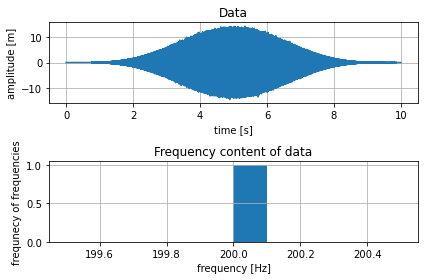

In [26]:
# set parameters
randomise = False # set to true to randomise the sine waves

number_of_sin_waves = 1 # arbitrary conditions
max_amp_sin_waves = 10
sampling_rate = 1e7

signal_duration = 10 # full signal duration, signal exists between delay and end
delay = 0
end = signal_duration

max_frequency = 200 # change frequency content. = frequency of non-randomised wave
band_range = 1

gaussian_noise_std = 1 # set the standard devaition of the noise

# generate data
nyquist_frequency = sampling_rate/2

data, t_plot, frequencies = sound_wave(
    max_amp_sin_waves, max_frequency, signal_duration, 
    sampling_rate, number_of_sin_waves, band_range, delay, 
    end, randomise
    )
print('data generated')
gaussian_noise = noise(gaussian_noise_std,signal_duration,sampling_rate)
print('noise generated')
data += gaussian_noise
print('noise added')
data = window(data)
print('data windowed')

fig, ax = plt.subplots(2,1)

ax[0].plot(t_plot,data)
ax[0].set_xlabel('time [s]')
ax[0].set_ylabel('amplitude [m]')
ax[0].set_title('Data')
ax[0].grid(True)

ax[1].hist(frequencies)
ax[1].set_xlabel('frequency [Hz]')
ax[1].set_ylabel('frequnecy of frequencies')
ax[1].set_title('Frequency content of data')
ax[1].grid(True)

fig.tight_layout()

plt.show()

# for future plots
if randomise:
    bandwidth_low = max_frequency*(1-band_range)
    title = f"- signal bandwidth = {bandwidth_low}-{max_frequency} Hz"
else:
    title = f"- signal frequency = {max_frequency} Hz"

## Appendix
code of the haar transform in java from wikipedia

This code is a very basic implementation of the haar wavelet transform. It doesn't deal with datasets of arbitrary length and doesn't account for the "energy" of the wave by multiplying by $\sqrt{2}$.

public static int[] discreteHaarWaveletTransform(int[] input) {
    // This function assumes that input.length=2^n, n>1
    int[] output = new int[input.length];

    for (int length = input.length / 2; ; length = length / 2) {
        // length is the current length of the working area of the output array.
        // length starts at half of the array size and every iteration is halved until it is 1.
        for (int i = 0; i < length; ++i) {
            int sum = input[i * 2] + input[i * 2 + 1];
            int difference = input[i * 2] - input[i * 2 + 1];
            output[i] = sum;
            output[length + i] = difference;
        }
        if (length == 1) {
            return output;
        }

        //Swap arrays to do next iteration
        System.arraycopy(output, 0, input, 0, length);
    }
}

In [27]:
# D4-D20 coefficients from wikipedia
# 
# 1	0.6830127	0.47046721	0.32580343	0.22641898	0.15774243	0.11009943	0.07695562	0.05385035	0.03771716
# 1	1.1830127	1.14111692	1.01094572	0.85394354	0.69950381	0.56079128	0.44246725	0.34483430	0.26612218
#     0.3169873	0.650365	0.89220014	1.02432694	1.06226376	1.03114849	0.95548615	0.85534906	0.74557507
#     −0.1830127−0.19093442	−0.03957503	0.19576696	0.44583132	0.66437248	0.82781653	0.92954571	0.97362811
#              −0.12083221	−0.26450717	−0.34265671	−0.31998660	−0.20351382	−0.02238574	0.18836955	0.39763774
#                 0.0498175	0.0436163	−0.04560113	−0.18351806	−0.31683501	−0.40165863	−0.41475176	−0.35333620
#                       0.0465036	0.10970265	0.13788809	0.1008467	6.68194092 × 10−4 −0.13695355	−0.27710988
#                           −0.01498699	−0.00882680	0.03892321	0.11400345	0.18207636	0.21006834	0.18012745
#                                       −0.01779187	−0.04466375	−0.05378245	−0.02456390	0.043452675	0.13160299
#                                     4.71742793 × 10−3	7.83251152 × 10−4	−0.02343994	−0.06235021	−0.09564726	−0.10096657
#                                     6.75606236 × 10−3	0.01774979	0.01977216	3.54892813 × 10−4	−0.04165925
#                                    −1.52353381 × 10−3	6.07514995 × 10−4	0.01236884	0.03162417	0.04696981
#                                        −2.54790472 × 10−3	−6.88771926 × 10−3	−6.67962023 × 10−3	5.10043697 × 10−3
#                                         5.00226853 × 10−4	−5.54004549 × 10−4	−6.05496058 × 10−3	−0.01517900
#                                                             9.55229711 × 10−4	2.61296728 × 10−3	1.97332536 × 10−3
#                                                             −1.66137261 × 10−4	3.25814671 × 10−4	2.81768659 × 10−3
#                                                                                 −3.56329759 × 10−4	−9.69947840 × 10−4
#                                                                                 5.5645514 × 10−5	−1.64709006 × 10−4
#                                                                                                     1.32354367 × 10−4
#                                                                                                     −1.875841 × 10−5